In [1]:
# Imports

import pandas as pd
import json
import matplotlib.pyplot as plt

In [2]:
# Load

with open("data/weather.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data["hourly"], columns=["time", "temperature_2m"])

df["time"] = pd.to_datetime(df["time"], unit="s", utc=True)
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df.head()

,time,temperature_2m
0,2000-01-01 00:00:00-07:00,-4.5
1,2000-01-01 01:00:00-07:00,-4.6
2,2000-01-01 02:00:00-07:00,-4.7
3,2000-01-01 03:00:00-07:00,-6.9
4,2000-01-01 04:00:00-07:00,-7.2


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max())
print("Latitude:", data["latitude"], " Longitude:", data["longitude"], "\n")

print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any())

2000-01-01 00:00:00-07:00 to 2026-09-30 23:00:00-06:00
Latitude: 51.0  Longitude: -114.0 

Shape: (234479, 2) 

Dtypes:
time              datetime64[s, America/Edmonton]
temperature_2m                            float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False


In [4]:
df[["temperature_2m"]].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m,234479.0,4.709839,11.51252,-42.9,-2.2,5.1,12.7,38.2


In [5]:
# Clean
# No clean required after inspection.

In [6]:
# Transform

filter_df = df.loc[df["time"].between(
        pd.Timestamp("2025-01-01", tz="America/Edmonton"), 
        pd.Timestamp("2026-01-01", tz="America/Edmonton"),
        inclusive = "left")].copy()

filter_df["date"] = filter_df["time"].dt.date

temp_df = (filter_df.groupby(["date"], as_index = False)
                    .agg(min_temp = ("temperature_2m", "min"),
                         max_temp = ("temperature_2m", "max"),
                         min_idx = ("temperature_2m", "idxmin"),
                         max_idx = ("temperature_2m", "idxmax"))
                    .assign(temp_diff = lambda x: x["max_temp"] - x["min_temp"],
                            min_temp_hour = lambda x: x["min_idx"].map(df["time"]).dt.hour,
                            max_temp_hour = lambda x: x["max_idx"].map(df["time"]).dt.hour)
                    .loc[:, ["date", "temp_diff", "min_temp", "min_temp_hour", "max_temp", "max_temp_hour"]]
)

output_df = temp_df.nlargest(10, "temp_diff").assign(rank = range(1, 11))

output_df

,date,temp_diff,min_temp,min_temp_hour,max_temp,max_temp_hour,rank
361,2025-12-28,27.4,-31.6,1,-4.2,16,1
107,2025-04-18,24.5,-5.8,6,18.7,18,2
93,2025-04-04,24.3,-15.4,7,8.9,17,3
262,2025-09-20,22.3,6.9,6,29.2,16,4
267,2025-09-25,22.1,4.2,3,26.3,17,5
158,2025-06-08,22.1,5.8,6,27.9,18,6
346,2025-12-13,21.8,-20.1,4,1.7,22,7
238,2025-08-27,21.7,8.5,7,30.2,15,8
50,2025-02-20,21.4,-15.7,0,5.7,15,9
122,2025-05-03,21.4,5.4,6,26.8,15,10


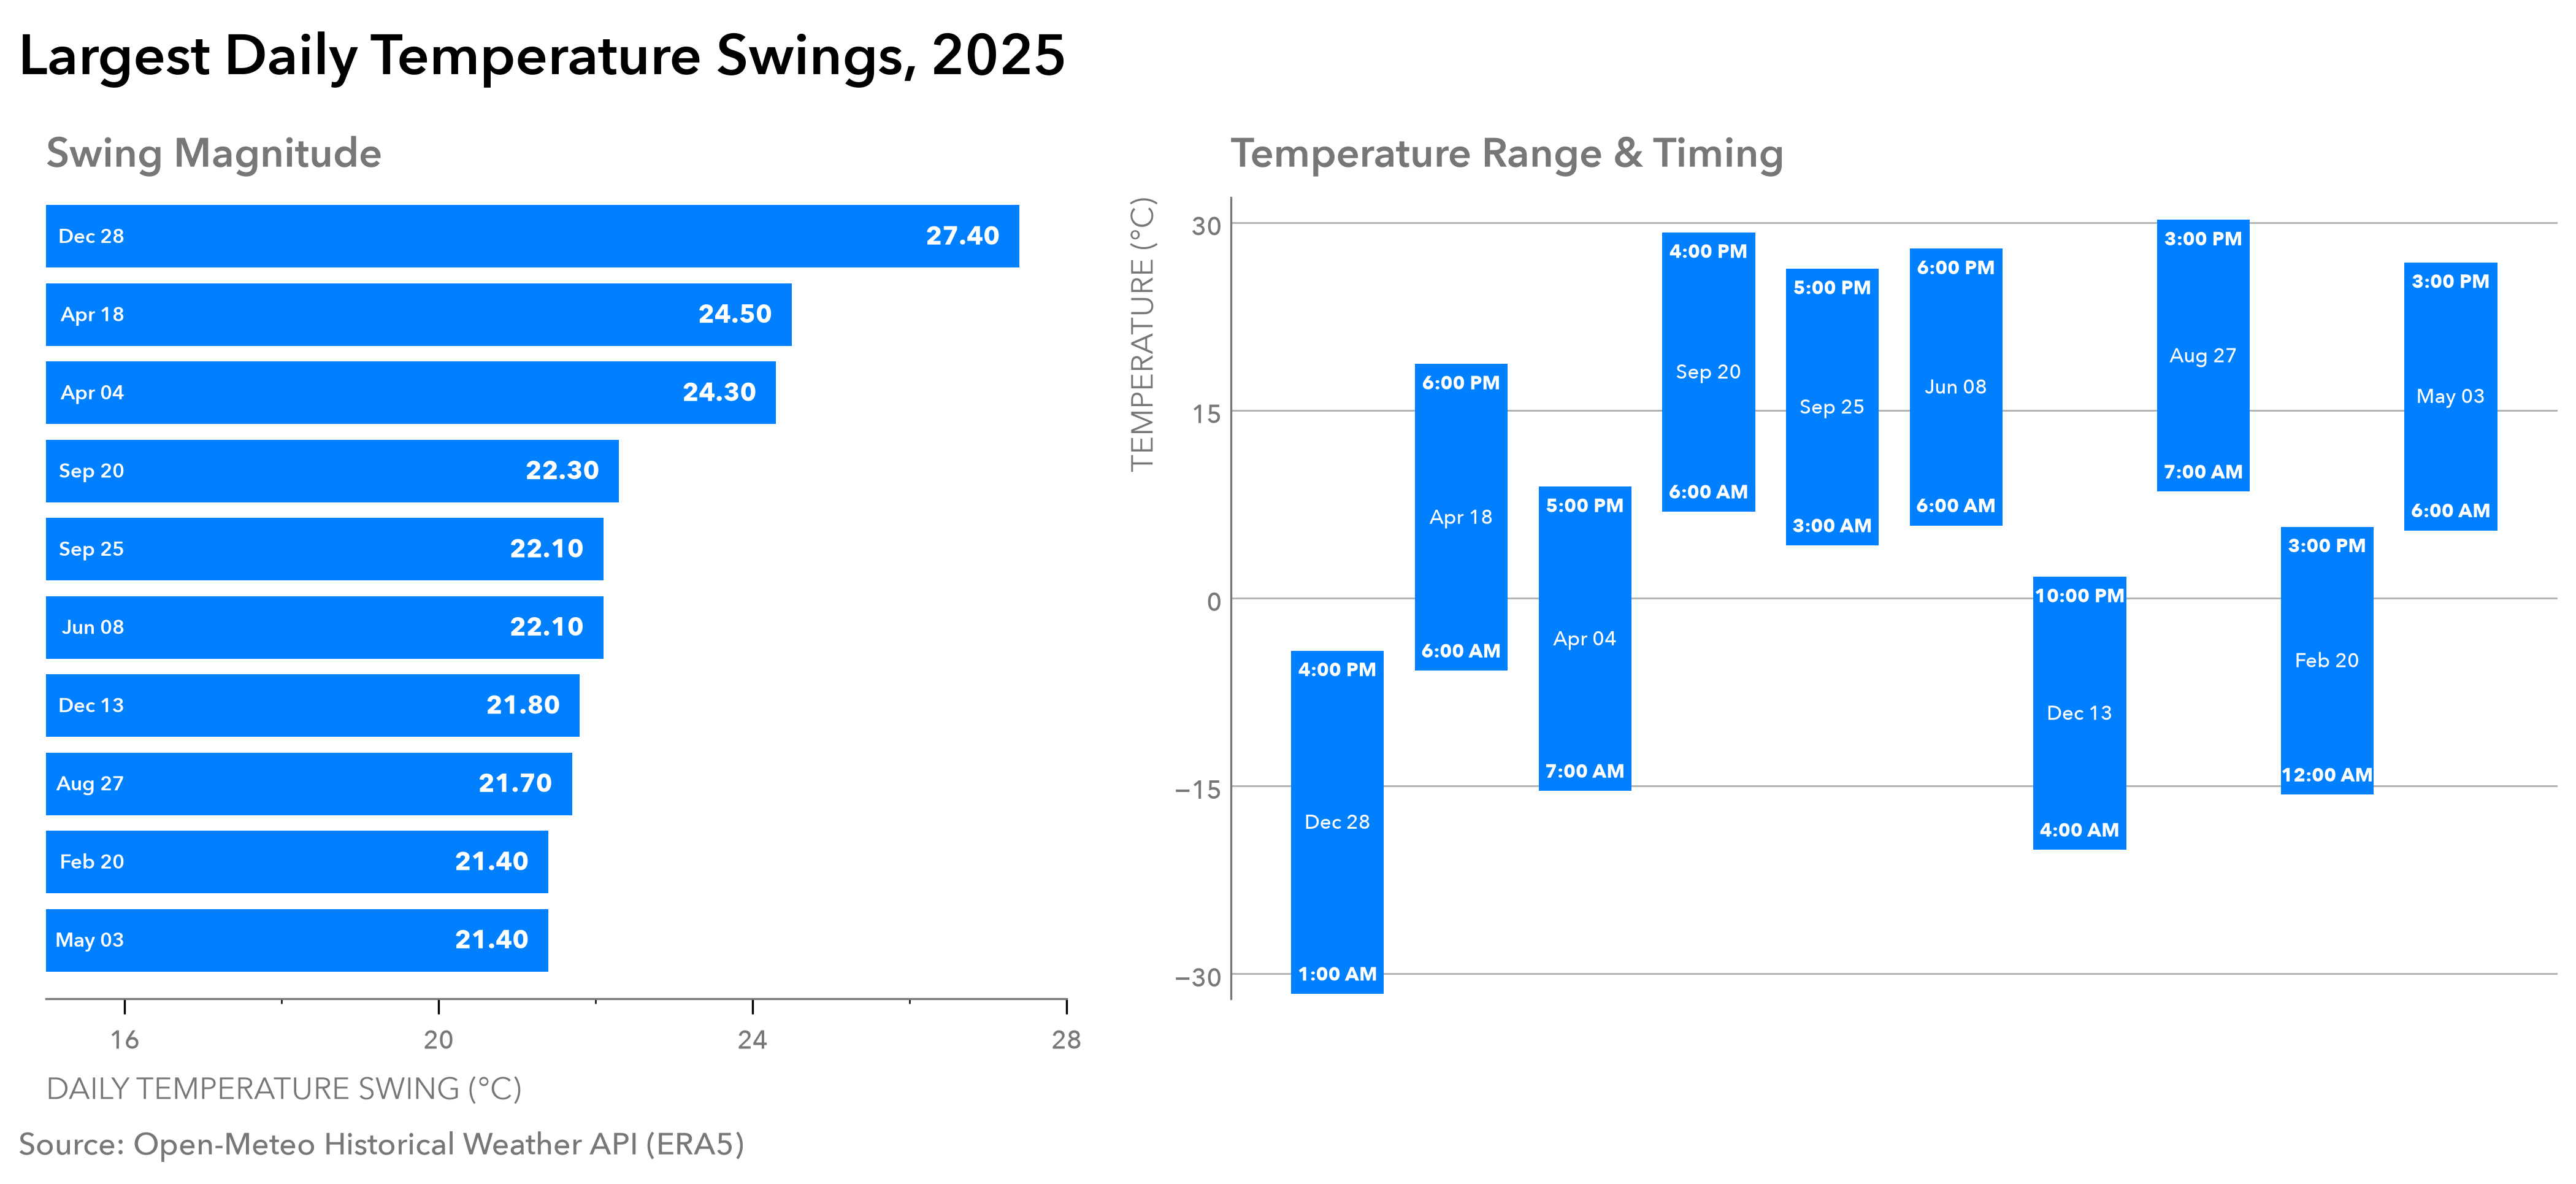

In [79]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15, 6.5), dpi = 300, gridspec_kw = {"width_ratios": [1, 1.3]})

fig.subplots_adjust(
    left = 0.07,
    right = 0.98,
    top = 0.80,
    bottom = 0.13,
    wspace = 0.14
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
BARS = "#0080FF"
BAR_LABEL = "#FFFFFF"

# Plot

bars = ax1.barh(output_df["rank"], output_df["temp_diff"], height = 0.8, color = BARS)

range_bars = ax2.bar(output_df["rank"], output_df["temp_diff"], bottom = output_df["min_temp"], width = 0.75, color = BARS)

# Emphasis

# Scale & Axes

ax1.set_xlim(15, 28)

ax1.set_xlabel("DAILY TEMPERATURE SWING (°C)", loc = "left", fontsize = 12, fontweight = 400, color = STRUCTURE)

ax1.set_ylim(10.75, 0.5)

ax2.set_ylim(-32, 32)

ax2.set_ylabel("TEMPERATURE (°C)", loc = "top", fontsize = 12, fontweight = 400, color = STRUCTURE)

# left barh labels
for i, date in enumerate(output_df["date"]):
    ax1.text(16, i + 1, date.strftime("%b %d"), ha = "right", va = "center", fontsize = 8, fontweight = 600, color = BAR_LABEL)

for i, diff in enumerate(output_df["temp_diff"]):
    ax1.text(diff - 0.25, i + 1, f"{diff:.2f}", ha = "right", va = "center", fontsize = 10, fontweight = 700, color = BAR_LABEL)

# hour formatting function
def format_hour(hour):
    display_hour = hour % 12 or 12
    period = "AM" if hour < 12 else "PM"
    
    return f"{display_hour}:00 {period}"

# right bar labels
for i, min_hour in enumerate(output_df["min_temp_hour"]):
    ax2.text(i + 1, output_df["min_temp"].iloc[i] + 0.5, format_hour(min_hour), ha = "center", va = "bottom", fontsize = 7.5, fontweight = 700, color = BAR_LABEL)

for i, date in enumerate(output_df["date"]):
    ax2.text(i + 1, output_df["min_temp"].iloc[i] + output_df["temp_diff"].iloc[i] / 2, date.strftime("%b %d"), ha = "center", va = "center", fontsize = 8, fontweight = 500, color = BAR_LABEL)

for i, max_hour in enumerate(output_df["max_temp_hour"]):
    ax2.text(i + 1, output_df["max_temp"].iloc[i] - 0.5, format_hour(max_hour), ha = "center", va = "top", fontsize = 7.5, fontweight = 700, color = BAR_LABEL)

# Ticks

ax1.set_xticks([16, 20, 24, 28])
ax1.set_xticks([18, 22, 26], minor = True)

ax1.tick_params(axis = "y", length = 0, labelleft = False)
ax1.tick_params(axis = "x", labelsize = 10, length = 6, labelcolor = STRUCTURE)

ax2.set_xticks([])
ax2.set_yticks([-30, -15, 0, 15, 30])

ax2.tick_params(axis = "x", length = 0)
ax2.tick_params(axis = "y", labelsize = 10, length = 0, labelcolor = STRUCTURE)

# Styling

ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.spines["bottom"].set_color(STRUCTURE)
ax1.spines["bottom"].set_linewidth(0.8)

ax2.spines[["top", "right", "bottom"]].set_visible(False)
ax2.spines["left"].set_color(STRUCTURE)
ax2.spines["left"].set_linewidth(0.8)

ax2.set_axisbelow(True)
ax2.grid(axis = "y", which = "major", color = GRID, linewidth = 0.7)

# Composition

fig.suptitle("Largest Daily Temperature Swings, 2025", x = 0.06, y = 0.95, ha = "left", va = "top", fontweight = 600, fontsize = 22)

ax1.set_title("Swing Magnitude", loc = "left", fontsize = 16, fontweight = 600, color = STRUCTURE, pad = 12)
ax2.set_title("Temperature Range & Timing", loc = "left", fontsize = 16, fontweight = 600, color = STRUCTURE, pad = 12)

fig.text(0.06, 0, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 12, color = STRUCTURE)

# Output

fig.savefig("outputs/largest-daily-temperature-swings-2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()